# Plot Simulation Results

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from matplotlib.gridspec import GridSpec
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import matplotlib.ticker as ticker

In [4]:
project_folder = os.getcwd()
if os.path.basename(project_folder) == "analysis":
    project_folder = os.path.dirname(project_folder)

results_dir = os.path.join(project_folder, "output", "results")
figures_dir = os.path.join(project_folder, "output", "figures")

df = pd.read_csv(os.path.join(results_dir, "simulation_sequential.csv"))
df["p_g_prop"] = df["p_g"] / df["p_d"]
df["L_prop"] = df["lexicon_size"] / (df["n"] + 855)

print(df.shape)
df.head()

(1000000, 12)


,n,p_d,p_g,shape_parameter,p_no,lexicon_size,m,generic,emergence,type,p_g_prop,L_prop
0,8,0.016146,0.003558,1.759059,0.184372,589,3,present,early,two level,0.220360,0.682503
1,174,0.277003,0.076612,8.898927,0.819755,835,2,present,early,two level,0.276574,0.811467
2,75,0.278222,0.064522,5.181650,0.799125,586,3,present,early,two level,0.231908,0.630108
3,13,0.073489,0.060573,7.414671,0.213763,445,1,present,early,two level,0.824242,0.512673
4,398,0.049771,0.024776,1.843380,0.582725,290,3,present,early,two level,0.497789,0.231445


## Plot 1: Proportions of presence and early emergence of generic as a function of each predictor

Plots showing the proportions of presence and early emergence of generic as a function of each binned parameter. Each panel is a stacked bar / line chart with shaded uncertainty.

22798


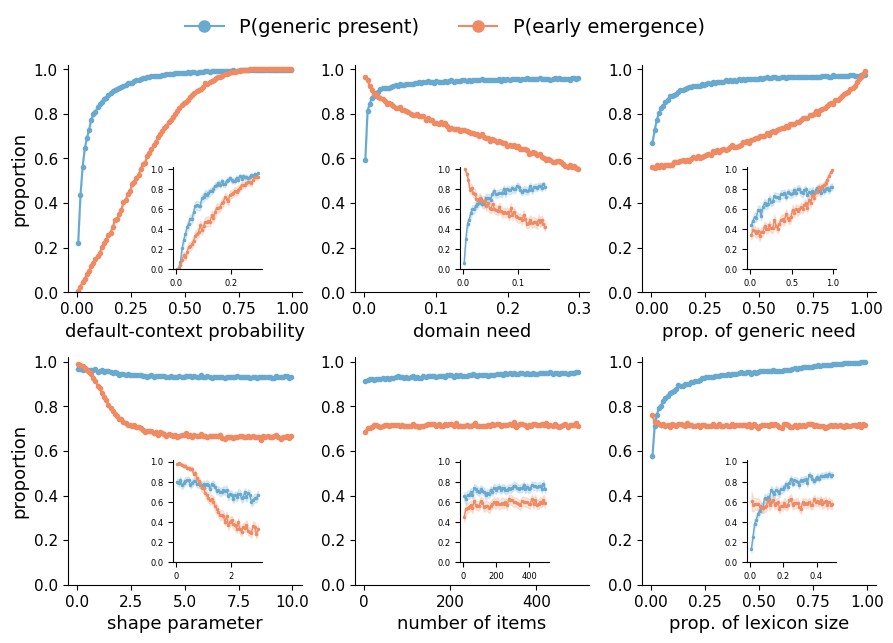

Saved: /Users/temuulenkh/Documents/github/superordinates/output/figures/presence_emergence.pdf


In [5]:
def plot_proportions_combined_with_inset(df, n_bins=100, figsize=(12, 7), exclude_none_emergence=True):
    df_full = df.copy()
    df_zoom = df[(df["p_no"] < 0.30) & (df["p_d"] < 0.15) &
                 (df["shape_parameter"] < 3) & (df["L_prop"] < 0.50)].copy()
    print(len(df_zoom))

    outcomes = [
        ("generic_present", "P(generic present)", "#67a9cf"),
        ("early",           "P(early emergence)", "#ef8a62"),
    ]

    for data in [df_full, df_zoom]:
        data["generic_present"] = (data["generic"] == "present").astype(float)

    # exclude none for emergence (conditional on at least one domain term labeled)
    df_full_em = df_full[df_full["emergence"] != "none"].copy() if exclude_none_emergence else df_full.copy()
    df_zoom_em = df_zoom[df_zoom["emergence"] != "none"].copy() if exclude_none_emergence else df_zoom.copy()
    for data in [df_full_em, df_zoom_em]:
        data["early"] = (data["emergence"] == "early").astype(float)

    predictors = [
        ("p_no",            "default-context probability"),
        ("p_d",             "domain need"),
        ("p_g_prop",        "prop. of generic need"),
        ("shape_parameter", "shape parameter"),
        ("n",               "number of items"),
        ("L_prop",          "prop. of lexicon size"),
    ]

    def draw_lines(ax, data, pred_col, n_bins, markersize=3, linewidth=1.5,
                   data_em=None):
        for outcome_col, _, color in outcomes:
            plot_data = data_em if (outcome_col == "early" and data_em is not None) else data
            plot_data["_bin"] = pd.cut(plot_data[pred_col], bins=n_bins)
            agg = (
                plot_data.groupby("_bin", observed=True)[outcome_col]
                .agg(["mean", "sem"])
                .reset_index()
            )
            agg["mid"] = agg["_bin"].apply(lambda iv: iv.mid)
            agg = agg.dropna(subset=["mid"])
            ax.plot(agg["mid"], agg["mean"], marker="o", markersize=markersize,
                    color=color, linewidth=linewidth)
            ax.fill_between(
                agg["mid"],
                (agg["mean"] - 1.96 * agg["sem"]).clip(0, 1.02),
                (agg["mean"] + 1.96 * agg["sem"]).clip(0, 1.02),
                alpha=0.2, color=color
            )
            plot_data.drop(columns=["_bin"], inplace=True)

    fig, axes = plt.subplots(2, 3, figsize=figsize)

    for pred_idx, (pred_col, pred_label) in enumerate(predictors):
        row = pred_idx // 3
        col = pred_idx % 3
        ax = axes[row, col]

        draw_lines(ax, df_full, pred_col, n_bins, data_em=df_full_em)

        ax.set_ylim(0, 1.02)
        ax.set_xlabel(pred_label, fontsize=13)
        ax.set_ylabel("proportion" if col == 0 else "", fontsize=13)
        ax.tick_params(axis="both", labelsize=11)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        # Inset: right-bottom
        inset = ax.inset_axes([0.45, 0.10, 0.38, 0.45])
        draw_lines(inset, df_zoom, pred_col, n_bins // 2, markersize=1.5, linewidth=1.0, data_em=df_zoom_em)
        inset.set_ylim(0, 1.02)
        inset.tick_params(axis="both", labelsize=6)
        inset.spines["top"].set_visible(False)
        inset.spines["right"].set_visible(False)

    handles = [
        plt.Line2D([0], [0], color=color, linewidth=1.5,
                   marker="o", markersize=8, label=label)
        for _, label, color in outcomes
    ]
    fig.legend(handles=handles, loc="upper center", ncol=2,
               fontsize=14, frameon=False, bbox_to_anchor=(0.5, 1.08))

    plt.tight_layout()
    return fig

fig1 = plot_proportions_combined_with_inset(df, n_bins=100, figsize=(9, 6), exclude_none_emergence=True)
plt.show()

out_path = os.path.join(figures_dir, "presence_emergence.pdf")
fig1.savefig(out_path, dpi=300, bbox_inches="tight")
plt.close(fig1)
print("Saved:", out_path)

## Plot 2: Mean count of specific labels as a function of each predictor

Shows the mean number of labeled specific items as a function of each of the
six binned predictors, with 95% CI bands.

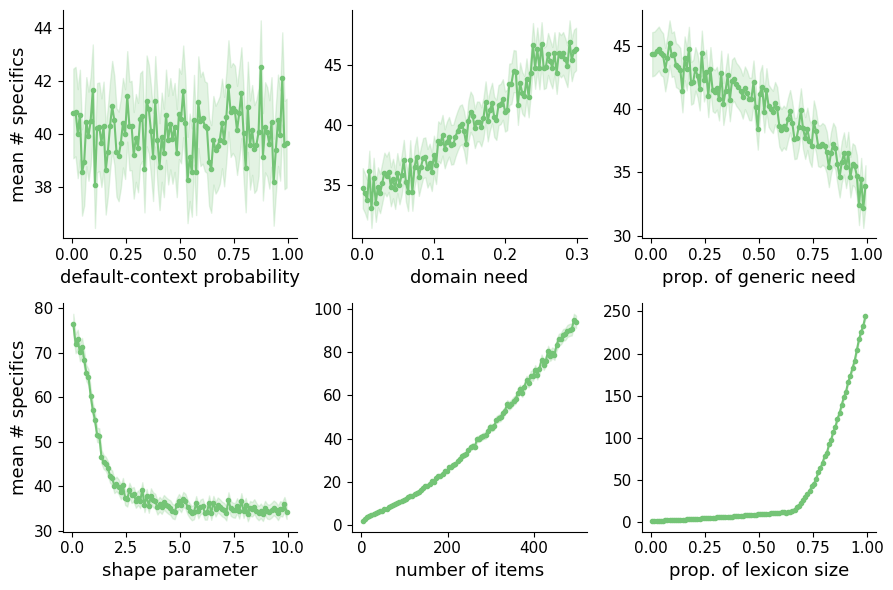

Saved: /Users/temuulenkh/Documents/github/superordinates/output/figures/specifics.pdf


In [6]:
def plot_m_by_predictor(df, n_bins=100, figsize=(12, 7)):
    df = df.copy()

    predictors = [
        ("p_no",            "default-context probability"),
        ("p_d",             "domain need"),
        ("p_g_prop",        "prop. of generic need"),
        ("shape_parameter", "shape parameter"),
        ("n",               "number of items"),
        ("L_prop",          "prop. of lexicon size"),
    ]

    fig, axes = plt.subplots(2, 3, figsize=figsize)

    for pred_idx, (pred_col, pred_label) in enumerate(predictors):
        row = pred_idx // 3
        col = pred_idx % 3
        ax = axes[row, col]

        df["_bin"] = pd.cut(df[pred_col], bins=n_bins)
        agg = (
            df.groupby("_bin", observed=True)["m"]
            .agg(["mean", "sem"])
            .reset_index()
        )
        agg["mid"] = agg["_bin"].apply(lambda iv: iv.mid)
        agg = agg.dropna(subset=["mid"])

        ax.plot(agg["mid"], agg["mean"], marker="o", markersize=3,
                color="#74c476", linewidth=1.5)
        ax.fill_between(
            agg["mid"],
            (agg["mean"] - 1.96 * agg["sem"]).clip(0),
            agg["mean"] + 1.96 * agg["sem"],
            alpha=0.2, color="#74c476"
        )

        ax.set_xlabel(pred_label, fontsize=13)
        ax.set_ylabel("mean # specifics" if col == 0 else "", fontsize=13)
        ax.tick_params(axis="both", labelsize=11)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        df.drop(columns=["_bin"], inplace=True)

    plt.tight_layout()
    return fig


fig2 = plot_m_by_predictor(df, n_bins=100, figsize=(9, 6))
plt.show()

out_path = os.path.join(figures_dir, "specifics.pdf")
fig2.savefig(out_path, dpi=300, bbox_inches="tight")
plt.close(fig2)
print("Saved:", out_path)

## Plot 3: System type proportions as a function of each predictor

Shows P(generic only), P(two level), and P(specific only) as a function of
each of the six binned predictors. Three lines per panel, one per system type.
Simulations where type = 'none' are excluded from the denominator so proportions
reflect meaningful lexical systems only.

22798


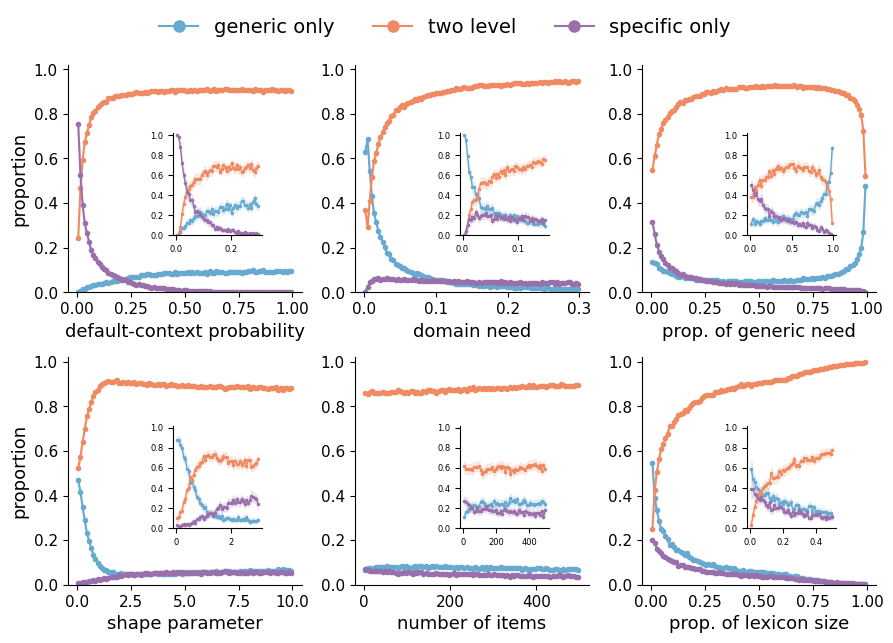

Saved: /Users/temuulenkh/Documents/github/superordinates/output/figures/system_type.pdf


In [7]:
def plot_system_type_with_inset(df, n_bins=100, figsize=(12, 7), exclude_none=True):
    df_full = df.copy()
    df_zoom = df[(df["p_no"] < 0.30) & (df["p_d"] < 0.15) &
                 (df["shape_parameter"] < 3) & (df["L_prop"] < 0.50)].copy()
    print(len(df_zoom))

    if exclude_none:
        df_full = df_full[df_full["type"] != "none"]
        df_zoom = df_zoom[df_zoom["type"] != "none"]

    system_types = ["generic only", "two level", "specific only"]
    type_colors  = {
        "generic only":  "#67a9cf",
        "two level":     "#ef8a62",
        "specific only": "#9970ab",
    }

    for stype in system_types:
        df_full[stype] = (df_full["type"] == stype).astype(float)
        df_zoom[stype] = (df_zoom["type"] == stype).astype(float)

    predictors = [
        ("p_no",            "default-context probability"),
        ("p_d",             "domain need"),
        ("p_g_prop",        "prop. of generic need"),
        ("shape_parameter", "shape parameter"),
        ("n",               "number of items"),
        ("L_prop",          "prop. of lexicon size"),
    ]

    def get_agg(data, pred_col, stype, n_bins):
        data["_bin"] = pd.cut(data[pred_col], bins=n_bins)
        agg = (
            data.groupby("_bin", observed=True)[stype]
            .agg(["mean", "sem"])
            .reset_index()
        )
        agg["mid"] = agg["_bin"].apply(lambda iv: iv.mid)
        agg = agg.dropna(subset=["mid"])
        data.drop(columns=["_bin"], inplace=True)
        return agg

    def draw_lines(ax, data, pred_col, n_bins, markersize=3, linewidth=1.5):
        for stype in system_types:
            agg = get_agg(data, pred_col, stype, n_bins)
            ax.plot(agg["mid"], agg["mean"], marker="o", markersize=markersize,
                    color=type_colors[stype], linewidth=linewidth)
            ax.fill_between(
                agg["mid"],
                (agg["mean"] - 1.96 * agg["sem"]).clip(0, 1.02),
                (agg["mean"] + 1.96 * agg["sem"]).clip(0, 1.02),
                alpha=0.15, color=type_colors[stype]
            )

    fig, axes = plt.subplots(2, 3, figsize=figsize)

    for pred_idx, (pred_col, pred_label) in enumerate(predictors):
        row = pred_idx // 3
        col = pred_idx % 3
        ax = axes[row, col]

        draw_lines(ax, df_full, pred_col, n_bins)

        ax.set_ylim(0, 1.02)
        ax.set_xlabel(pred_label, fontsize=13)
        ax.set_ylabel("proportion" if col == 0 else "", fontsize=13)
        ax.tick_params(axis="both", labelsize=11)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        # Inset: right-center, 38% wide, 45% tall
        inset = ax.inset_axes([0.45, 0.25, 0.38, 0.45])
        draw_lines(inset, df_zoom, pred_col, n_bins // 2, markersize=1.5, linewidth=1.0)
        inset.set_ylim(0, 1.02)
        inset.tick_params(axis="both", labelsize=6)
        inset.spines["top"].set_visible(False)
        inset.spines["right"].set_visible(False)

    handles = [
        plt.Line2D([0], [0], color=type_colors[s], linewidth=1.5,
                   marker="o", markersize=8, label=s)
        for s in system_types
    ]
    fig.legend(handles=handles, loc="upper center", ncol=len(system_types),
               fontsize=14, frameon=False, bbox_to_anchor=(0.5, 1.08))

    plt.tight_layout()
    return fig


fig3 = plot_system_type_with_inset(df, n_bins=100, figsize=(9, 6), exclude_none=True)
plt.show()

out_path = os.path.join(figures_dir, "system_type.pdf")
fig3.savefig(out_path, dpi=300, bbox_inches="tight")
plt.close(fig3)
print("Saved:", out_path)

## Plot 4: Relation between generic and number of specifics

/var/folders/s4/dzqp3h_n4k17cqyfz623c1480000gn/T/ipykernel_92607/2540632478.py:24: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(vals, ax=ax, color=color, fill=True, alpha=0.4, label=cat)


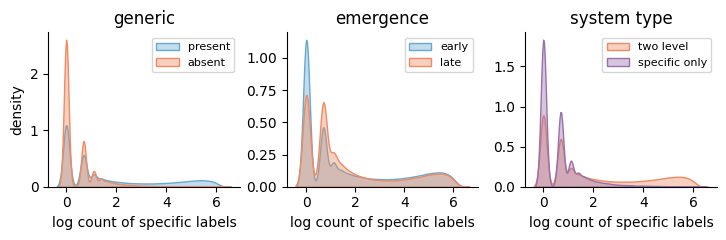

Saved: /Users/temuulenkh/Documents/github/superordinates/output/figures/generic_specifics.pdf


In [8]:
def plot_log_m_by_outcome(df, figsize=(10, 3)):
    df = df.copy()
    df["log_m"] = df["m"].apply(lambda x: 0 if x == 0 else np.log(x))

    df_sys = df[df["type"] != "none"]
    system_order = ["generic only", "two level", "specific only"]

    panels = [
    (df,     "generic",   ["present", "absent"],  "generic",
     ["#67a9cf", "#ef8a62"]),
    (df,     "emergence", ["early", "late"],       "emergence",
     ["#67a9cf", "#ef8a62"]),
    (df_sys, "type",      system_order,            "system type",
     ["#67a9cf", "#ef8a62", "#9970ab"]
),
]


    fig, axes = plt.subplots(1, 3, figsize=figsize)

    for ax, (plot_df, xvar, order, xlabel, colors) in zip(axes, panels):
        for cat, color in zip(order, colors):
            vals = plot_df.loc[plot_df[xvar] == cat, "log_m"].dropna()
            sns.kdeplot(vals, ax=ax, color=color, fill=True, alpha=0.4, label=cat)

        ax.set_xlabel("log count of specific labels")
        ax.set_ylabel("density" if ax is axes[0] else "")
        ax.set_title(xlabel)
        ax.legend(fontsize=8)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    plt.tight_layout()
    return fig


fig4 = plot_log_m_by_outcome(df, figsize=(7.5, 2.5))
plt.show()

out_path = os.path.join(figures_dir, "generic_specifics.pdf")
fig4.savefig(out_path, dpi=300, bbox_inches="tight")
plt.close(fig4)
print("Saved:", out_path)

## Plot 5: Interactions between predictors

In [9]:
def plot_majority_tiles(df, x_col, y_cols, y_labels, outcome_col, pos_val, neg_val,
                        pos_color='#67a9cf', neg_color='#ef8a62', empty_color='#dddddd',
                        n_bins=100, title=None, figsize=(8, 5), x_label=None, legend_title=None):
    plot_df = df[df[outcome_col].isin([pos_val, neg_val])].copy()
    y_bin = (plot_df[outcome_col] == pos_val).astype(int).values

    xvals = plot_df[x_col].values
    xedges = np.linspace(xvals.min(), xvals.max(), n_bins + 1)
    xi = np.clip(np.digitize(xvals, xedges) - 1, 0, n_bins - 1)

    cmap3 = ListedColormap([neg_color, empty_color, pos_color])

    ncols = 3
    nrows = int(np.ceil(len(y_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = axes.flatten()

    xlabel = x_label if x_label is not None else x_col

    for ax, ycol, ylabel in zip(axes, y_cols, y_labels):
        yvals = plot_df[ycol].values
        yedges = np.linspace(yvals.min(), yvals.max(), n_bins + 1)
        yi = np.clip(np.digitize(yvals, yedges) - 1, 0, n_bins - 1)

        pos_cnt = np.zeros((n_bins, n_bins))
        neg_cnt = np.zeros((n_bins, n_bins))
        np.add.at(pos_cnt, (xi, yi), y_bin)
        np.add.at(neg_cnt, (xi, yi), 1 - y_bin)

        total = pos_cnt + neg_cnt
        majority = np.where(total == 0,  0,
                   np.where(pos_cnt > neg_cnt,  1,
                   np.where(neg_cnt > pos_cnt, -1, 0)))

        ax.imshow(majority.T, origin='lower', aspect='auto',
                  extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
                  cmap=cmap3, vmin=-1, vmax=1, interpolation='nearest')
        ax.set_xlabel(xlabel, fontsize=11)
        ax.set_ylabel(ylabel, fontsize=11)
        ax.xaxis.set_major_locator(ticker.MaxNLocator(4))
        ax.yaxis.set_major_locator(ticker.MaxNLocator(4))

    legend_handles = [
        Patch(facecolor=pos_color,   label=pos_val),
        Patch(facecolor=neg_color,   label=neg_val),
        Patch(facecolor=empty_color, label='tie'),
    ]

    spare_axes = axes[len(y_cols):]
    if len(spare_axes) > 0:
        legend_ax = spare_axes[0]
        legend_ax.axis('off')
        legend_ax.legend(handles=legend_handles, title=legend_title,
                         loc='center', frameon=False, fontsize=12, title_fontsize=13)
        for ax in spare_axes[1:]:
            ax.set_visible(False)
    else:
        fig.legend(handles=legend_handles, title=legend_title,
                   loc='lower right', frameon=False, fontsize=12, title_fontsize=13)

    if title:
        fig.suptitle(title, fontsize=13, y=1.01)
    plt.tight_layout()
    return fig


In [10]:
def plot_majority_tiles_multi(df, x_col, y_cols, y_labels, outcome_col, classes, colors,
                              empty_color='#dddddd', n_bins=100, title=None,
                              figsize=(8, 5), x_label=None, legend_title=None):
    plot_df = df[df[outcome_col].isin(classes)].copy()

    xvals  = plot_df[x_col].values
    xedges = np.linspace(xvals.min(), xvals.max(), n_bins + 1)
    xi     = np.clip(np.digitize(xvals, xedges) - 1, 0, n_bins - 1)

    class_to_idx = {c: i for i, c in enumerate(classes)}
    y_class = np.array([class_to_idx[v] for v in plot_df[outcome_col]])

    ncols = 3
    nrows = int(np.ceil(len(y_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = axes.flatten()

    xlabel = x_label if x_label is not None else x_col

    for ax, ycol, ylabel in zip(axes, y_cols, y_labels):
        yvals  = plot_df[ycol].values
        yedges = np.linspace(yvals.min(), yvals.max(), n_bins + 1)
        yi     = np.clip(np.digitize(yvals, yedges) - 1, 0, n_bins - 1)

        counts = np.zeros((n_bins, n_bins, len(classes)), dtype=int)
        for k in range(len(classes)):
            mask = y_class == k
            np.add.at(counts[:, :, k], (xi[mask], yi[mask]), 1)

        total    = counts.sum(axis=2)
        majority = counts.argmax(axis=2)

        img = np.zeros((n_bins, n_bins, 4))
        for k, color in enumerate(colors):
            rgba = np.array(mcolors.to_rgba(color))
            mask = (majority == k) & (total > 0)
            img[mask] = rgba
        empty_rgba = np.array(mcolors.to_rgba(empty_color))
        img[total == 0] = empty_rgba

        ax.imshow(img.transpose(1, 0, 2), origin='lower', aspect='auto',
                  extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
                  interpolation='nearest')
        ax.set_xlabel(xlabel, fontsize=11)
        ax.set_ylabel(ylabel, fontsize=11)
        ax.xaxis.set_major_locator(ticker.MaxNLocator(4))
        ax.yaxis.set_major_locator(ticker.MaxNLocator(4))

    legend_handles = [Patch(facecolor=c, label=l) for c, l in zip(colors, classes)]
    legend_handles.append(Patch(facecolor=empty_color, label='tie'))

    spare_axes = axes[len(y_cols):]
    if len(spare_axes) > 0:
        legend_ax = spare_axes[0]
        legend_ax.axis('off')
        legend_ax.legend(handles=legend_handles, title=legend_title,
                         loc='center', frameon=False, fontsize=12, title_fontsize=13)
        for ax in spare_axes[1:]:
            ax.set_visible(False)
    else:
        fig.legend(handles=legend_handles, title=legend_title,
                   loc='lower right', frameon=False, fontsize=12, title_fontsize=13)

    if title:
        fig.suptitle(title, fontsize=13, y=1.01)
    plt.tight_layout()
    return fig


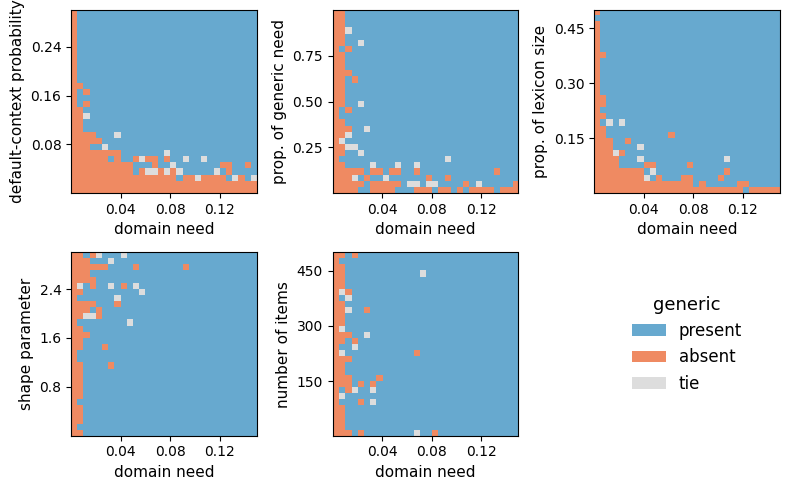

Saved: /Users/temuulenkh/Documents/github/superordinates/output/figures/interactions_generic.pdf


In [11]:
df_zoom = df[(df["p_no"] < 0.30) & (df["p_d"] < 0.15) &
             (df["shape_parameter"] < 3) & (df["L_prop"] < 0.50)].copy()

Y_COLS   = ["p_no", "p_g_prop", "L_prop", "shape_parameter", "n"]
Y_LABELS = [
    "default-context probability",
    "prop. of generic need",
    "prop. of lexicon size",
    "shape parameter",
    "number of items",
]

fig5 = plot_majority_tiles(
    df_zoom,
    x_col="p_d", x_label="domain need",
    y_cols=Y_COLS, y_labels=Y_LABELS,
    outcome_col="generic", pos_val="present", neg_val="absent",
    pos_color="#67a9cf", neg_color="#ef8a62",
    n_bins=30,
    legend_title="generic",
)
plt.show()

out_path = os.path.join(figures_dir, "interactions_generic.pdf")
fig5.savefig(out_path, dpi=300, bbox_inches="tight")
plt.close(fig5)
print("Saved:", out_path)


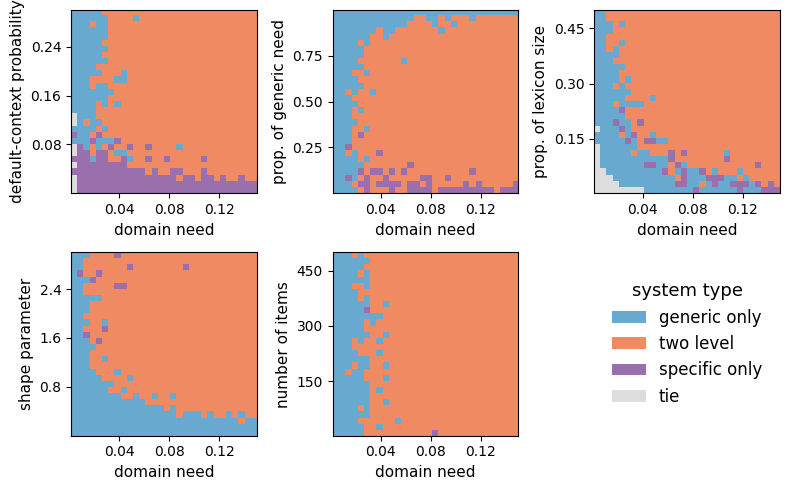

In [12]:
fig5b = plot_majority_tiles_multi(
    df_zoom[df_zoom["type"] != "none"],
    x_col="p_d", x_label="domain need",
    y_cols=Y_COLS, y_labels=Y_LABELS,
    outcome_col="type",
    classes=["generic only", "two level", "specific only"],
    colors=["#67a9cf", "#ef8a62", "#9970ab"],
    n_bins=30,
    figsize=(8, 5),
    legend_title="system type",
)
plt.show()

#out_path = os.path.join(figures_dir, "interactions_system.pdf")
#fig5b.savefig(out_path, dpi=300, bbox_inches="tight")
#plt.close(fig5b)
#print("Saved:", out_path)

## Table 1: Compare simple and sequential simulation results

In [13]:
df_simple = pd.read_csv(os.path.join(results_dir, "simulation_simple.csv"))
df_simple["p_g_prop"] = df_simple["p_g"] / df_simple["p_d"]
df_simple["L_prop"]   = df_simple["lexicon_size"] / (df_simple["n"] + 855)

type_order = ["generic only", "two level", "specific only"]

# ── 1. Generic presence ──────────────────────────────────────────────────────
generic_pct = pd.DataFrame({
    "Sequential (%)": df["generic"].value_counts(normalize=True).mul(100).round(2),
    "Simple (%)":     df_simple["generic"].value_counts(normalize=True).mul(100).round(2),
}).rename_axis("Generic").reset_index()

print("=== Generic presence (%) ===")
print(generic_pct.to_string(index=False))

# ── 2. Overall mean m ────────────────────────────────────────────────────────
print(f"\n=== Mean number of specifics (m) ===")
print(f"Sequential: {df['m'].mean():.3f}  |  Simple: {df_simple['m'].mean():.3f}")

# ── 3. System type distribution (excluding none, renormalized) ────────────────
seq_type_raw = df[df["type"] != "none"]["type"].value_counts(normalize=True).mul(100)
sim_type_raw = df_simple[df_simple["type"] != "none"]["type"].value_counts(normalize=True).mul(100)

type_pct = pd.DataFrame({
    "System type":    type_order,
    "Sequential (%)": [round(seq_type_raw.get(t, 0), 2) for t in type_order],
    "Simple (%)":     [round(sim_type_raw.get(t, 0), 2) for t in type_order],
})

print("\n=== System type distribution (%, none excluded, renormalized) ===")
print(type_pct.to_string(index=False))

# ── Write LaTeX table ─────────────────────────────────────────────────────────
tables_dir = os.path.join(project_folder, "output", "tables")
os.makedirs(tables_dir, exist_ok=True)

rows = []
rows.append(r"\multicolumn{3}{l}{\textit{Generic presence (\%)}} \\")
for _, r in generic_pct.iterrows():
    rows.append(f"\\quad {r['Generic']} & {r['Sequential (%)']:.2f} & {r['Simple (%)']:.2f} \\\\")

rows.append(r"\hline")
rows.append(r"\multicolumn{3}{l}{\textit{Mean number of specifics ($m$)}} \\")
rows.append(f"\\quad $\\bar{{m}}$ & {df['m'].mean():.3f} & {df_simple['m'].mean():.3f} \\\\")

rows.append(r"\hline")
rows.append(r"\multicolumn{3}{l}{\textit{System type (\%, excl.\ none, renormalized)}} \\")
for _, r in type_pct.iterrows():
    rows.append(f"\\quad {r['System type']} & {r['Sequential (%)']:.2f} & {r['Simple (%)']:.2f} \\\\")

latex = "\n".join([
    r"\begin{table}[ht]",
    r"\centering",
    r"\caption{Comparison of simple and sequential simulation results ($N = 1{,}000{,}000$).}",
    r"\label{tab:sim_comparison}",
    r"\begin{tabular}{lrr}",
    r"\hline",
    r"\textbf{Outcome} & \textbf{Sequential} & \textbf{Simple} \\",
    r"\hline",
    "\n".join(rows),
    r"\hline",
    r"\end{tabular}",
    r"\end{table}",
])

out_path = os.path.join(tables_dir, "simulation_comparison.tex")
with open(out_path, "w") as f:
    f.write(latex)

print(f"\nLaTeX table saved: {out_path}")

=== Generic presence (%) ===
Generic  Sequential (%)  Simple (%)
present           93.91       97.18
 absent            6.09        2.82

=== Mean number of specifics (m) ===
Sequential: 40.045  |  Simple: 40.804

=== System type distribution (%, none excluded, renormalized) ===
  System type  Sequential (%)  Simple (%)
 generic only            7.54        3.70
    two level           87.74       94.89
specific only            4.72        1.40

LaTeX table saved: /Users/temuulenkh/Documents/github/superordinates/output/tables/simulation_comparison.tex
